## **Juego Yahtzee para Dos Jugadores**

Este notebook contiene el juego básico y una sección de experimentación estadística. La simulación de Monte Carlo se ejecuta por separado: no inicia una partida interactiva y permite estudiar la probabilidad de obtener cinco dados iguales en un lanzamiento.

In [3]:

import random
from collections import Counter

# -----------------------------------------
# 1. Lanzamiento de dados
# -----------------------------------------
#Esta función simula cinco dados de seis caras. Cada cara tiene una probabilidad de (1/6).
# La función random.randint(1, 6) permite obtener cualquiera de los seis resultados posibles.
# Para el modelo de simulación, se asume que los dados son independientes y justos.

def lanzar_dados(cantidad=5):
    return [random.randint(1, 6) for _ in range(cantidad)]

# -----------------------------------------
# 2. Conservar dados y relanzar los demás
# -----------------------------------------
# El jugador podrá conservar los dados que desee. Los demás se vuelven a lanzar.

def relanzar_dados(dados):
    print("Dados actuales:", dados)
    entrada = input(
        "Posiciones que desea conservar (1-5, separadas por comas). "
        "Enter para relanzar todos: "
    )

    try:
        posiciones = set()
        if entrada.strip():
            posiciones = {
                int(x.strip()) - 1
                for x in entrada.split(",")
            }

        if any(p < 0 or p >= 5 for p in posiciones):
            print("Posiciones inválidas. Se conservan todos los dados.")
            return dados

    except ValueError:
        print("Entrada inválida. Se conservan todos los dados.")
        return dados

    conservados = [
        dado for i, dado in enumerate(dados)
        if i in posiciones
    ]

    nuevos = lanzar_dados(5 - len(conservados))
    resultado = sorted(conservados + nuevos)

    print("Resultado del relanzamiento:", resultado)
    return resultado


# -----------------------------------------
# 3. Calcular combinaciones
# -----------------------------------------
# El Yahtzee clásico tiene 13 categorías de puntuación: seis categorías numéricas y siete categorías especiales.
# Cada categoría puede utilizarse una sola vez por jugador. Las combinaciones especiales incluyen trío,
# póquer, full house, escalera pequeña, escalera grande, Yahtzee y oportunidad.

def calcular_puntaje(dados, categoria):
    conteo = Counter(dados)
    frecuencias = sorted(conteo.values())
    total = sum(dados)

    # Categorías numéricas: 1, 2, 3, 4, 5 o 6
    if categoria in range(1, 7):
        return categoria * conteo[categoria]

    if categoria == "trio":
        return total if max(frecuencias) >= 3 else 0

    if categoria == "poker":
        return total if max(frecuencias) >= 4 else 0

    if categoria == "full":
        return 25 if frecuencias == [2, 3] else 0

    if categoria == "escalera_pequena":
        valores = set(dados)
        secuencias = [
            {1, 2, 3, 4},
            {2, 3, 4, 5},
            {3, 4, 5, 6}
        ]
        return 30 if any(
            s.issubset(valores) for s in secuencias
        ) else 0

    if categoria == "escalera_grande":
        return 40 if (
            len(set(dados)) == 5
            and set(dados) in (
                {1, 2, 3, 4, 5},
                {2, 3, 4, 5, 6}
            )
        ) else 0

    if categoria == "yahtzee":
        return 50 if len(conteo) == 1 else 0

    if categoria == "oportunidad":
        return total

    raise ValueError("Categoría desconocida")


# -----------------------------------------
# 4. Categorías de puntuación
# -----------------------------------------
CATEGORIAS = {
    "1": (1, "Uno"),
    "2": (2, "Dos"),
    "3": (3, "Tres"),
    "4": (4, "Cuatro"),
    "5": (5, "Cinco"),
    "6": (6, "Seises"),
    "7": ("trio", "Trío"),
    "8": ("poker", "Póquer"),
    "9": ("full", "Full house"),
    "10": ("escalera_pequena", "Escalera pequeña"),
    "11": ("escalera_grande", "Escalera grande"),
    "12": ("yahtzee", "Yahtzee"),
    "13": ("oportunidad", "Oportunidad")
}


# -----------------------------------------
# 5. Ejecutar un turno
# -----------------------------------------
def jugar_turno(nombre, tarjeta):
    print(f"\n--- Turno de {nombre} ---")

    dados = lanzar_dados()
    print("Primer lanzamiento:", dados)

    for intento in range(2):
        respuesta = input(
            "¿Desea relanzar dados? (s/n): "
        ).strip().lower()

        if respuesta != "s":
            break

        dados = relanzar_dados(dados)

    print("\nResultado final:", dados)

    disponibles = {
        k: v for k, v in CATEGORIAS.items()
        if k not in tarjeta
    }

    print("\nCategorías disponibles:")
    for clave, (_, nombre_categoria) in disponibles.items():
        print(f"{clave}. {nombre_categoria}")

    while True:
        opcion = input("Seleccione una categoría: ").strip()

        if opcion in disponibles:
            break

        print("Opción inválida. Intente nuevamente.")

    categoria, nombre_categoria = disponibles[opcion]
    puntos = calcular_puntaje(dados, categoria)

    tarjeta[opcion] = puntos

    print(f"Categoría: {nombre_categoria}")
    print(f"Puntos obtenidos: {puntos}")
    print(f"Total acumulado: {sum(tarjeta.values())}")


# -----------------------------------------
# 6. Partida para dos jugadores
# -----------------------------------------
def jugar():
    jugadores = ["Jugador 1", "Jugador 2"]
    tarjetas = {nombre: {} for nombre in jugadores}

    # Cada jugador dispone de 3 turnos
    for ronda in range(1, 4):
        print(f"\n{'=' * 35}")
        print(f"RONDA {ronda} DE 3")
        print("=" * 35)

        for nombre in jugadores:
            jugar_turno(nombre, tarjetas[nombre])

    print("\n========== RESULTADOS FINALES ==========")

    totales = {}

    for nombre in jugadores:
        tarjeta = tarjetas[nombre]

        puntos_superiores = sum(
            tarjeta.get(str(n), 0)
            for n in range(1, 7)
        )

        bono = 35 if puntos_superiores >= 63 else 0
        total = sum(tarjeta.values()) + bono
        totales[nombre] = total

        print(f"\n{nombre}")
        print("Puntos de categorías:", sum(tarjeta.values()))
        print("Bono sección superior:", bono)
        print("Puntuación final:", total)

    if totales[jugadores[0]] > totales[jugadores[1]]:
        print("\n¡Gana el Jugador 1!")
    elif totales[jugadores[1]] > totales[jugadores[0]]:
        print("\n¡Gana el Jugador 2!")
    else:
        print("\n¡La partida termina en empate!")


# -----------------------------------------
# 7. Iniciar el programa
# -----------------------------------------
if __name__ == "__main__":
    jugar()



RONDA 1 DE 3

--- Turno de Jugador 1 ---
Primer lanzamiento: [5, 3, 6, 2, 5]
¿Desea relanzar dados? (s/n): s
Dados actuales: [5, 3, 6, 2, 5]
Posiciones que desea conservar (1-5, separadas por comas). Enter para relanzar todos: 1,3,4,5
Resultado del relanzamiento: [2, 2, 5, 5, 6]
¿Desea relanzar dados? (s/n): s
Dados actuales: [2, 2, 5, 5, 6]
Posiciones que desea conservar (1-5, separadas por comas). Enter para relanzar todos: 1, 2, 3, 4, 5
Resultado del relanzamiento: [2, 2, 5, 5, 6]

Resultado final: [2, 2, 5, 5, 6]

Categorías disponibles:
1. Uno
2. Dos
3. Tres
4. Cuatro
5. Cinco
6. Seises
7. Trío
8. Póquer
9. Full house
10. Escalera pequeña
11. Escalera grande
12. Yahtzee
13. Oportunidad
Seleccione una categoría: 13
Categoría: Oportunidad
Puntos obtenidos: 20
Total acumulado: 20

--- Turno de Jugador 2 ---
Primer lanzamiento: [5, 1, 3, 1, 2]


KeyboardInterrupt: Interrupted by user

**Experimento de Monte Carlo: Probabiliad de Yahtzee.**

Estimar mediante simulación la probabilidad de que, al lanzar cinco dados justos de seis caras una sola vez, los cinco muestren el mismo valor.
Probabilidad teórica
Hay \(6^5 = 7776\) resultados ordenados igualmente probables para cinco dados. Los casos favorables son seis: todos unos, todos doses, ..., todos seises.

Por tanto:

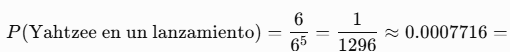 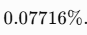


Esta probabilidad se refiere a un solo lanzamiento de cinco dados, no a un turno que permite hasta tres lanzamientos.

Metodología
1. Simular lanzamientos independientes de cinco dados.
2. Contar un éxito cuando los cinco valores son iguales.
3. Calcular la frecuencia relativa: éxitos / número de simulaciones.
4. Comparar la frecuencia con el valor teórico y visualizar su evolución al aumentar el número de simulaciones.

La semilla aleatoria se fija para que los resultados puedan reproducirse al ejecutar nuevamente la celda con el mismo código.

In [17]:
import random
import matplotlib.pyplot as plt

# Parámetros del experimento
N = 1_000_000
SEMILLA = 42
PROB_TEORICA = 1 / 1296

# Generador con semilla para poder reproducir el experimento
rng = random.Random(SEMILLA)

exitos = 0
cantidades = []
frecuencias = []
exitos_en_corte = []

# Guardar la frecuencia acumulada cada 1.000 simulaciones
paso = 1_000

for i in range(1, N + 1):
    dados = [rng.randint(1, 6) for _ in range(5)]

    if dados[0] == dados[1] == dados[2] == dados[3] == dados[4]:
        exitos += 1

    if i % paso == 0:
        cantidades.append(i)
        frecuencias.append(exitos / i)
        exitos_en_corte.append(exitos)

prob_experimental = exitos / N
error_absoluto = abs(prob_experimental - PROB_TEORICA)

print("RESULTADOS DE MONTE CARLO")
print("-" * 42)
print(f"Semilla utilizada:             {SEMILLA}")
print(f"Número de simulaciones:        {N:,}")
print(f"Yahtzees observados:           {exitos:,}")
print(f"Probabilidad teórica:          {PROB_TEORICA:.8%}")
print(f"Probabilidad experimental:     {prob_experimental:.8%}")
print(f"Error absoluto:                {error_absoluto:.8%}")
print(f"Error absoluto en puntos %:    {error_absoluto * 100:.6f}")


RESULTADOS DE MONTE CARLO
------------------------------------------
Semilla utilizada:             42
Número de simulaciones:        1,000,000
Yahtzees observados:           709
Probabilidad teórica:          0.07716049%
Probabilidad experimental:     0.07090000%
Error absoluto:                0.00626049%
Error absoluto en puntos %:    0.006260


**Gráfica 1. Convergencia de la frecuencia relativa.**

La gráfica compara la frecuencia relativa acumulada con la probabilidad teórica. La frecuencia experimental puede subir o bajar durante la ejecución; no se espera que cada punto esté más cerca que el anterior. La tendencia general, al aumentar el número de ensayos, debe aproximarse al valor teórico.


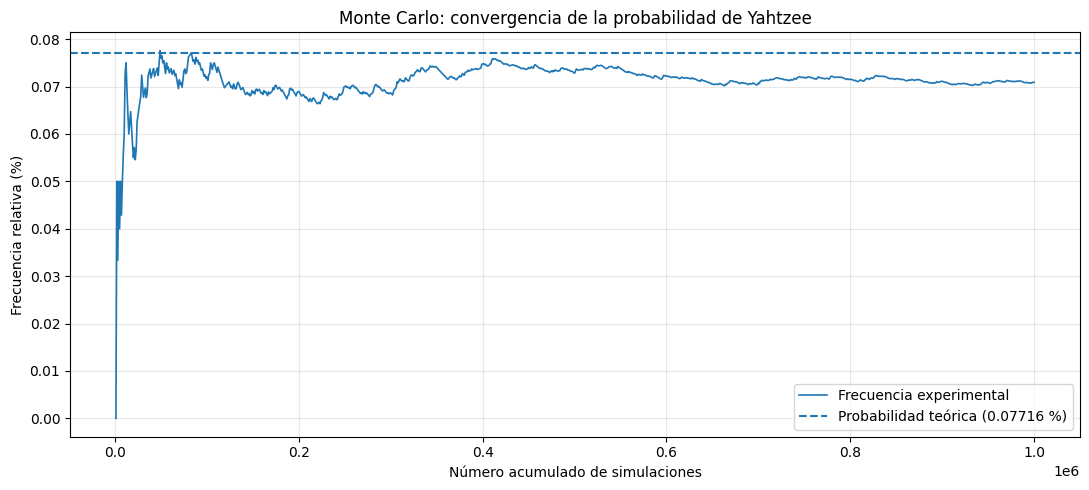

In [13]:
plt.figure(figsize=(11, 5))
plt.plot(
    cantidades,
    [p * 100 for p in frecuencias],
    label="Frecuencia experimental",
    linewidth=1.2
)
plt.axhline(
    y=PROB_TEORICA * 100,
    linestyle="--",
    label=f"Probabilidad teórica ({PROB_TEORICA * 100:.5f} %)"
)
plt.title("Monte Carlo: convergencia de la probabilidad de Yahtzee")
plt.xlabel("Número acumulado de simulaciones")
plt.ylabel("Frecuencia relativa (%)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Gráfica 2. Comparación en distintos tamaños de muestra.**

Esta segunda gráfica compara la frecuencia experimental en cuatro tamaños de muestra. Los resultados se toman de la misma simulación acumulada, por lo que cada tamaño corresponde a los primeros \(n\) experimentos de la secuencia.

   Simulaciones     Frecuencia experimental         Teórica
          1,000                  0.000000 %      0.077160 %
         10,000                  0.060000 %      0.077160 %
        100,000                  0.072000 %      0.077160 %
      1,000,000                  0.070900 %      0.077160 %


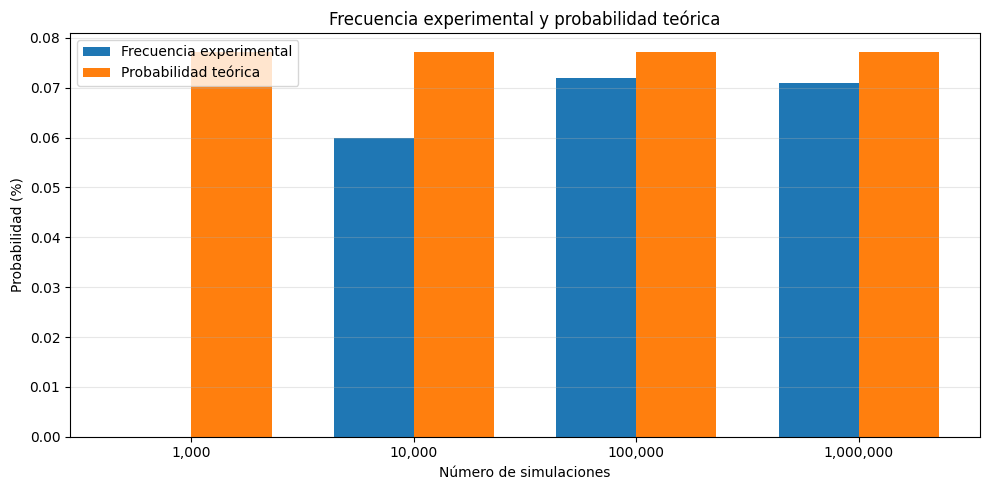

In [18]:
cortes = [1_000, 10_000, 100_000, 1_000_000]
frecuencias_corte = []

for n in cortes:
    # El índice corresponde al último punto guardado hasta ese tamaño de muestra
    indice = n // paso - 1
    frecuencias_corte.append(frecuencias[indice])

print(f"{'Simulaciones':>15} {'Frecuencia experimental':>27} {'Teórica':>15}")
for n, p in zip(cortes, frecuencias_corte):
    print(f"{n:>15,} {p * 100:>25.6f} % {PROB_TEORICA * 100:>13.6f} %")

posiciones = list(range(len(cortes)))
ancho = 0.36

plt.figure(figsize=(10, 5))
plt.bar(
    [p - ancho / 2 for p in posiciones],
    [p * 100 for p in frecuencias_corte],
    width=ancho,
    label="Frecuencia experimental"
)
plt.bar(
    [p + ancho / 2 for p in posiciones],
    [PROB_TEORICA * 100] * len(cortes),
    width=ancho,
    label="Probabilidad teórica"
)
plt.xticks(posiciones, [f"{n:,}" for n in cortes])
plt.title("Frecuencia experimental y probabilidad teórica")
plt.xlabel("Número de simulaciones")
plt.ylabel("Probabilidad (%)")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


**Interpretación de los resultados:**

- En 1.000.000 de simulaciones, se observaron [710] casos de cinco dados iguales.
- La frecuencia experimental fue [0.071%], mientras que la probabilidad teórica es aproximadamente 0,07716 %.
- La diferencia absoluta obtenida fue [0.00616%] calculada 0.071% - 0.07716%.

**Relación con la Teoría de los Grandes Números:**


La Teoría de los Grandes Números establece que, bajo condiciones de independencia y con una misma probabilidad de éxito, la frecuencia relativa de un evento tiende a su probabilidad teórica cuando crece el número de experimentos. Por eso, al aumentar la cantidad de lanzamientos simulados, la frecuencia observada suele estabilizarse alrededor de \(1/1296\).

La convergencia no implica que cada nueva medición sea más cercana que la anterior ni que el resultado experimental coincida exactamente con la probabilidad teórica. Las diferencias son normales en un experimento aleatorio.

**Conclusión**

La simulación de Monte Carlo permite aproximar empíricamente la probabilidad de obtener un Yahtzee en un lanzamiento. La comparación entre la frecuencia relativa y el valor teórico ilustra el comportamiento descrito por la Teoría de los Grandes Números.